In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

full = pd.read_csv("../data/raw/modeling_dataset_v1.csv", parse_dates=["date"], low_memory=False)
full["year"], full["month"] = full["date"].dt.year, full["date"].dt.month

ocean_cols = [c for c in full.columns if c.endswith(("_mean", "_p95", "_var"))]
eng_cols = ["doy_sin", "doy_cos", "day_length", "current_speed", "temp_strat", "temp_x_mld"]
feature_cols = ocean_cols + eng_cols

print(full.shape)
print(full["label"].value_counts())
print("missing values in features:", full[feature_cols].isna().sum().sum())

(18144, 41)
label
0    9580
1    8564
Name: count, dtype: int64
missing values in features: 0


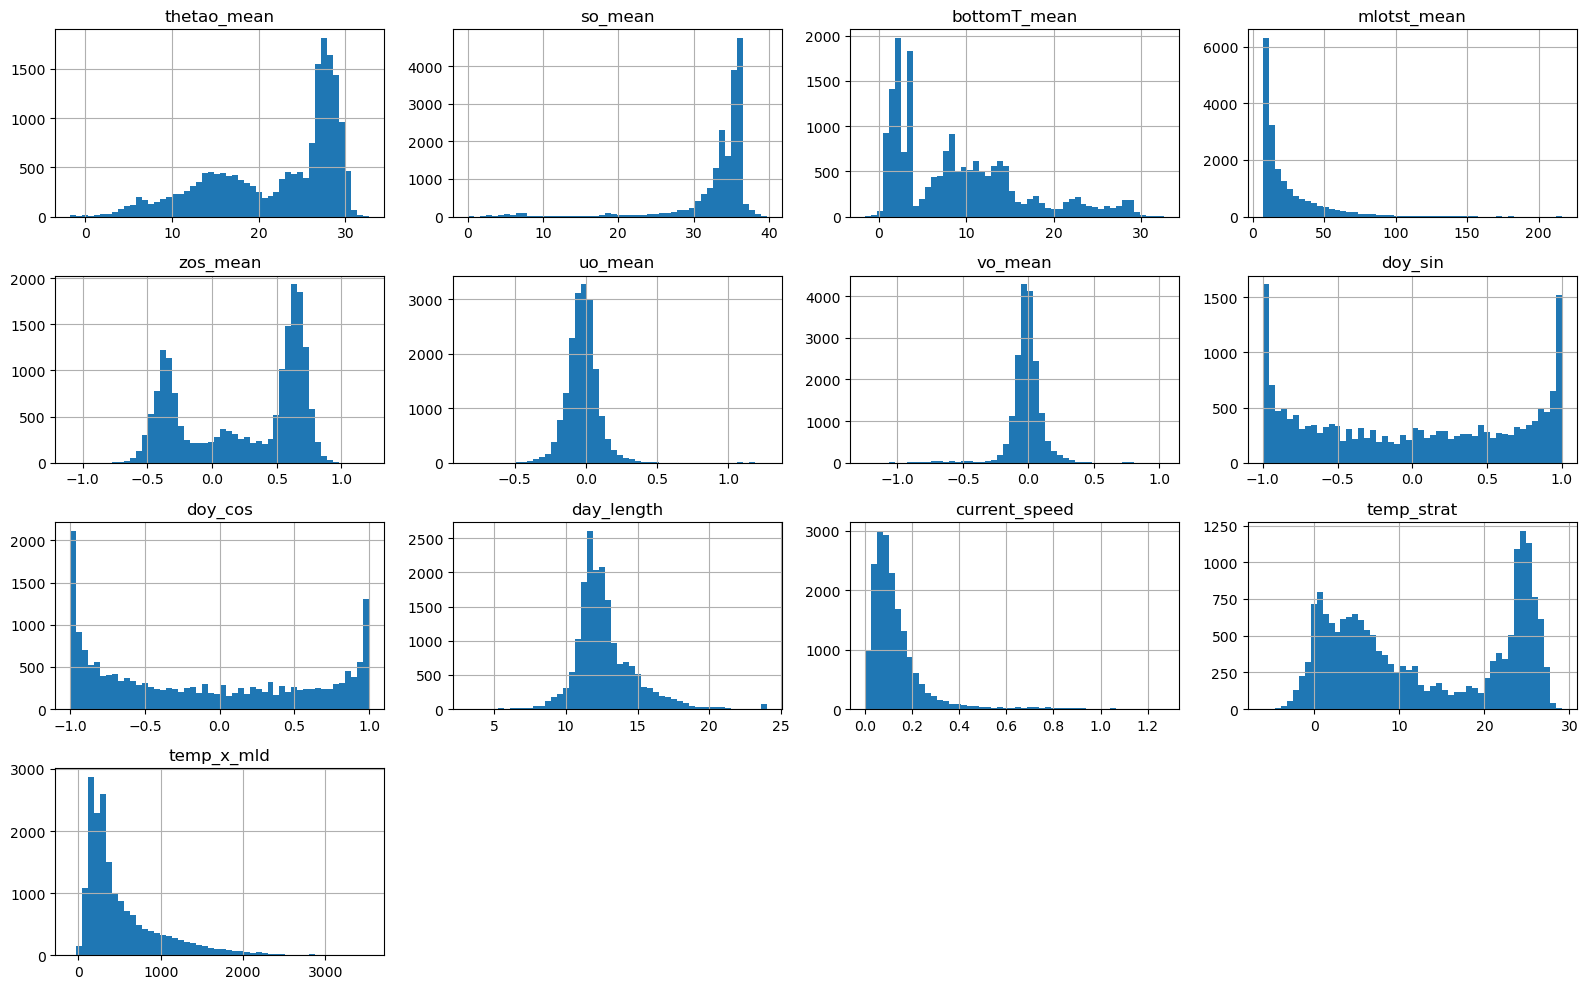

mlotst_var       16.03
zos_var          15.96
thetao_var       10.08
so_var           10.04
uo_var            9.98
vo_var            8.95
so_p95           -4.18
so_mean          -3.61
current_speed     3.60
uo_p95            3.46
dtype: float64

In [2]:
# feature distribution
full[[c for c in ocean_cols if c.endswith("_mean")] + eng_cols].hist(bins=50, figsize=(16, 10))
plt.tight_layout(); plt.show()
full[feature_cols].skew().round(2).sort_values(key=abs, ascending=False).head(10)

In [3]:
# Takeaways:
# - Two main location regimes show up: temperate vs. tropical and shallow shelf
#   vs. deep ocean. bottomT and temp_strat show this especially clearly.
# - zos looks bimodal too, but this seems more related to geography than blooms.
# - Low-salinity values likely come from estuaries or river-influenced areas.
# - The _var features are very skewed: most values are near 0 with a few large
#   values, likely from boxes crossing fronts or coastlines. Fine for trees;
#   log-transform if we try linear models.

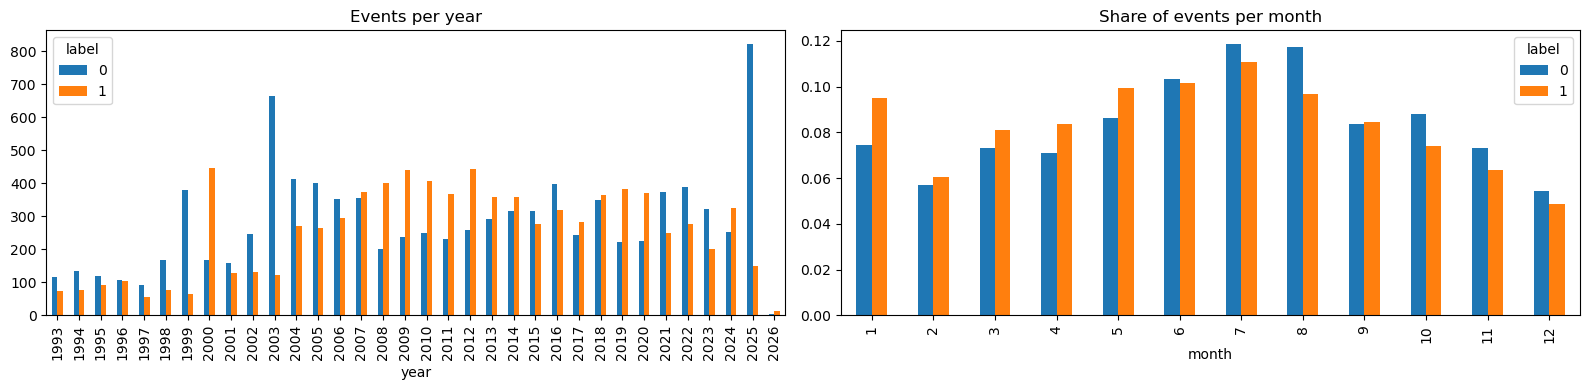

In [4]:
## 2. Are bloom and no-bloom spread similarly over time?
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
pd.crosstab(full["year"], full["label"]).plot(kind="bar", ax=ax[0], title="Events per year")
pd.crosstab(full["month"], full["label"], normalize="columns").plot(kind="bar", ax=ax[1], title="Share of events per month")
plt.tight_layout(); plt.show()

In [5]:
for y in [1999, 2003, 2025]:
    print(y, full[(full["year"] == y) & (full["label"] == 0)]["Country"].value_counts().head(3).to_dict())

1999 {'FRENCH POLYNESIA': 263, 'PHILIPPINES': 55, 'TURKEY': 16}
2003 {'FRENCH POLYNESIA': 433, 'PHILIPPINES': 66, 'SPAIN': 38}
2025 {'FRENCH POLYNESIA': 731, 'NORWAY': 47, 'PHILIPPINES': 23}


In [6]:
# Takeaways:
# - Month distributions are similar by design because negatives were sampled
#   from months when blooms occur at the same site.
# - Year distributions are much less balanced, especially in 1999, 2003, and 2025
#   (~15% positive vs. 73% in 2000). 2026 has only 17 rows.
# - Cause (checked in extract_negative_features.py): negatives get their real
#   calendar date, but the 30-day exclusion rejects almost every day in years
#   when a busy site had many blooms (e.g. FP site -17,-142.5: 0% of days allowed
#   in 2010/2018). Retries then pile negatives into that site's quiet years
#   (1999, 2003, 2025). The country fallback is only ~5% of negatives.
# - So "quiet year at a busy site" is baked into the labels. The model can learn
#   year-level conditions (e.g. warming trends) instead of bloom conditions, and
#   quiet years may be reporting gaps, i.e. unreported blooms labeled negative.
# - Under leave-future-out CV, each test fold has a different positive rate
#   (2025 = 973 rows at 15% positive), so use PR-AUC/ROC-AUC per fold, not accuracy.
# - French Polynesia explains most of this imbalance (34% of all rows), so test
#   the model with and without FP and consider balancing its negatives by year.

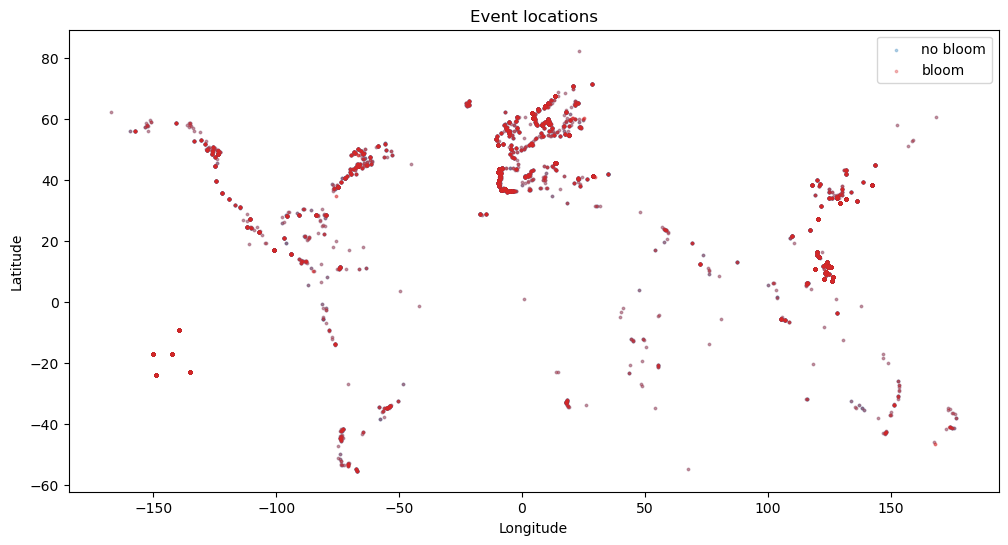

In [7]:
## 3. Where are the events?

plt.figure(figsize=(12, 6))
for lab, name, c in [(0, "no bloom", "tab:blue"), (1, "bloom", "tab:red")]:
    d = full[full["label"] == lab]
    plt.scatter(d["Longitude"], d["Latitude"], s=3, alpha=0.3, c=c, label=name)
plt.legend(); plt.title("Event locations"); plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()

In [8]:
# Takeaways:
# - The positive and negative points overlap quite a bit, which is expected
#   because the negatives were created from the same sites as the blooms.
# - Most of the data is concentrated around Europe, North America, East Asia,
#   the Philippines, Chile, and Australia. There is much less coverage in
#   Africa, the Indian Ocean, and other parts of the tropics.
# - This is probably partly a reporting/monitoring issue with HAEDAT, so we
#   should be careful about assuming the model will work equally well in areas
#   with very little data.
# - Leave-future-out stays the main evaluation; a spatial/region split is a
#   useful secondary check for how the model does in under-sampled regions.

In [9]:
## 4. Which features differ most between bloom and no-bloom?
diff = (full.groupby("label")[feature_cols].mean().diff().iloc[-1]
        / full[feature_cols].std()).sort_values(key=abs, ascending=False)
diff.round(2)

bottomT_p95     -0.24
temp_strat       0.22
bottomT_mean    -0.19
zos_mean         0.11
thetao_mean      0.11
thetao_p95       0.11
zos_p95          0.11
temp_x_mld       0.10
bottomT_var     -0.10
doy_sin          0.10
uo_p95          -0.09
so_mean          0.07
mlotst_var      -0.07
uo_mean         -0.07
so_p95           0.06
uo_var          -0.06
mlotst_mean      0.05
current_speed   -0.04
day_length       0.03
thetao_var      -0.03
vo_var          -0.03
doy_cos          0.03
so_var          -0.03
zos_var         -0.02
vo_p95          -0.00
mlotst_p95      -0.00
vo_mean         -0.00
dtype: float64

In [10]:
site = full["Latitude"].round(1).astype(str) + "_" + full["Longitude"].round(1).astype(str)
anom = full[feature_cols] - full.groupby(site)[feature_cols].transform("mean")

diff_anom = (anom.groupby(full["label"]).mean().diff().iloc[-1]
             / anom.std()).sort_values(key=abs, ascending=False)
diff_anom.round(2).head(10)

doy_sin        0.11
zos_mean      -0.09
day_length     0.09
zos_p95       -0.09
mlotst_p95    -0.08
mlotst_mean   -0.07
temp_x_mld    -0.07
mlotst_var    -0.05
uo_p95        -0.04
so_mean       -0.04
dtype: float64

In [11]:
per_site = full.groupby(site)["label"].agg(["mean", "count"])
print(per_site["mean"].describe())
print("sites that are all-negative:", (per_site["mean"] == 0).sum())

count    879.000000
mean       0.469414
std        0.104410
min        0.250000
25%        0.428571
50%        0.500000
75%        0.500000
max        1.000000
Name: mean, dtype: float64
sites that are all-negative: 0


In [12]:
# - Site balance: the median site is about 50% positive, but positive share
#   ranges from 0.25 to 1.0. Some sites have many more negatives than positives,
#   while a few have no negatives at all.
# - This could explain some of the between-site signal, so per-site balancing
#   is worth testing.

share non-null by label:
       span_days  event_ids  n_records  n_toxic  species
label                                                   
0           0.00        0.0        0.0      0.0     0.00
1           0.34        1.0        1.0      1.0     0.47
label              0     1
date_precision            
ambiguous          0    43
day             9580  8010
long_span          0   112
month              0   399
year    1993    1994    1995    1996    1997    1998    1999    2000    2001  \
mean    0.38    0.37    0.43    0.49    0.38    0.32    0.15    0.73    0.44   
size  190.00  211.00  212.00  210.00  148.00  246.00  446.00  615.00  286.00   

year    2002  ...    2017    2018    2019    2020   2021    2022    2023  \
mean    0.34  ...    0.54    0.51    0.63    0.62    0.4    0.42    0.38   
size  377.00  ...  525.00  715.00  604.00  596.00  622.0  666.00  523.00   

year    2024    2025   2026  
mean    0.56    0.15   0.82  
size  576.00  973.00  17.00  

[2 rows x 34 columns]
Fr

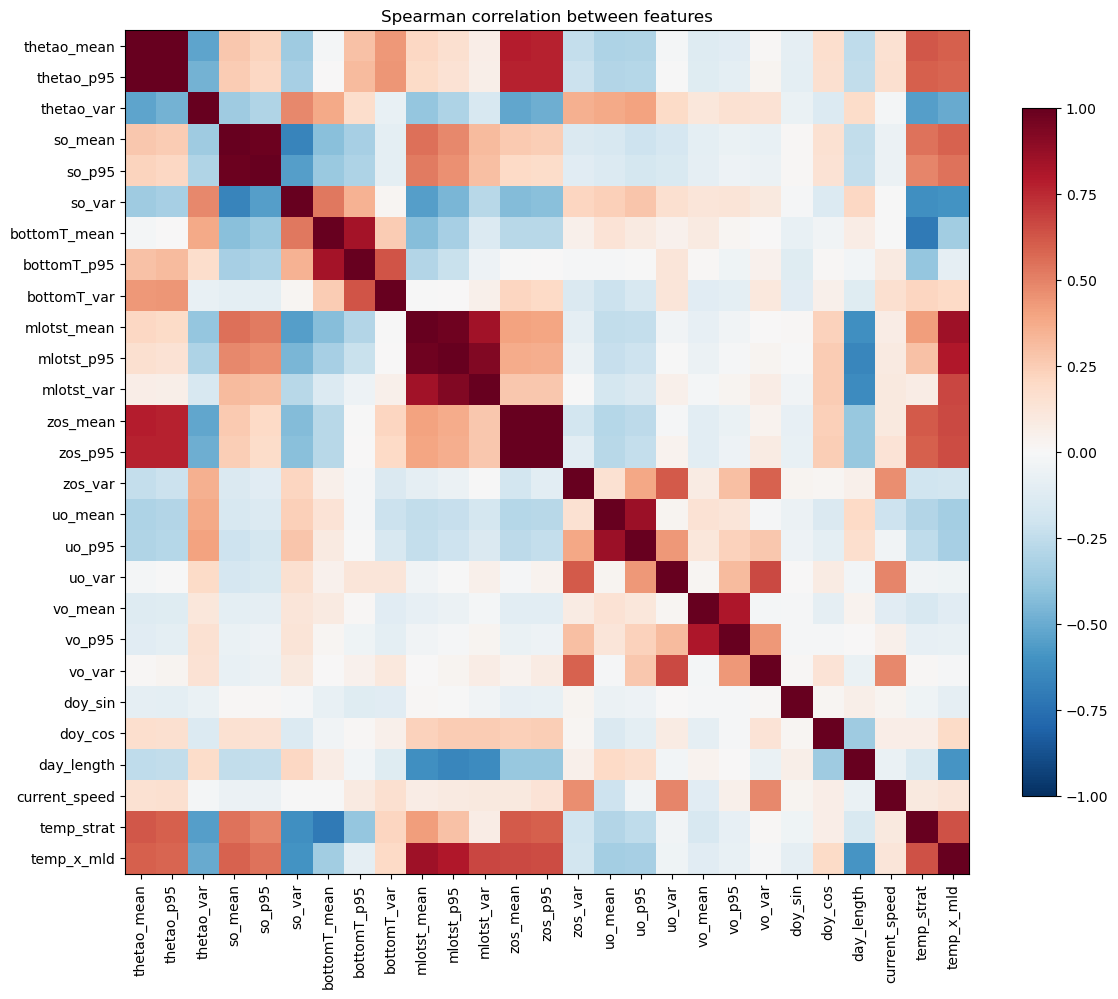

thetao_mean   thetao_p95     0.997
zos_mean      zos_p95        0.993
so_mean       so_p95         0.979
mlotst_mean   mlotst_p95     0.970
mlotst_p95    mlotst_var     0.926
uo_mean       uo_p95         0.858
mlotst_mean   temp_x_mld     0.845
              mlotst_var     0.842
bottomT_mean  bottomT_p95    0.833
vo_mean       vo_p95         0.810
mlotst_p95    temp_x_mld     0.803
dtype: float64

In [13]:
## 5. Data quality checks

# leakage: non-feature columns that are only filled for blooms
meta_cols = ["span_days", "event_ids", "n_records", "n_toxic", "species"]
print("share non-null by label:")
print(full.groupby("label")[meta_cols].agg(lambda s: s.notna().mean()).round(2))
print(pd.crosstab(full["date_precision"], full["label"]))

# positive rate per year (what each leave-future-out fold sees)
print(full.groupby("year")["label"].agg(["mean", "size"]).round(2).T)

print("French Polynesia share of rows:", round((full["Country"] == "FRENCH POLYNESIA").mean(), 3))
print("duplicate site+date rows:", full.duplicated(["Latitude", "Longitude", "date"]).sum())

# redundancy across all features (Spearman, since _var is very skewed)
corr = full[feature_cols].corr(method="spearman")
plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(shrink=0.8)
plt.xticks(range(len(feature_cols)), feature_cols, rotation=90)
plt.yticks(range(len(feature_cols)), feature_cols)
plt.title("Spearman correlation between features")
plt.tight_layout(); plt.show()

pairs = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pairs[pairs > 0.8].sort_values(ascending=False).round(3)

In [14]:
## 6. Summary

# Dataset: 18,144 rows (8,564 blooms, 9,580 no-bloom), 27 features, no missing values,
# no duplicate site+date rows.
#
# Design:
# - Negatives come from the same bloom sites on non-bloom days, matched to bloom
#   months and kept 30+ days from a bloom.
# - This makes the current dataset better for asking "WHEN is a known site at risk?"
#   rather than "WHERE will a bloom happen?"
#
# Main findings:
# - Strong differences exist between location types (temperate/tropical,
#   shallow/deep), and _var features are highly skewed.
# - Month distributions are balanced by design, but year distributions are not
#   (positive rate ranges from 15% to 73% by year). French Polynesia is 34% of rows.
# - Geographic coverage follows HAEDAT reporting patterns and is uneven.
# - Global bloom/no-bloom differences mostly disappear when comparing within
#   the same site, suggesting limited day-to-day signal from the current features.
# - doy_sin is the strongest within-site signal. This may be an artifact of the
#   30-day exclusion pushing negatives to the edges of the bloom season, not biology.
# - Redundant features (Spearman |r| > 0.8):
#   - _mean vs _p95 for thetao (0.997), zos (0.993), so (0.979), mlotst (0.970),
#     uo, bottomT, vo.
#   - mlotst_mean/p95/var all move together, and temp_x_mld is mostly mlotst (0.85).
#   - thetao_mean vs zos_mean (Pearson 0.80), likely both tracking tropical vs temperate.
#   - bottomT vs temp_strat is NOT redundant (< 0.8).
#
# Leakage warning - never use these as features:
# - event_ids, n_records, n_toxic, span_days, species: only filled for blooms.
# - date_precision: every negative is "day"; only blooms are month/ambiguous/long_span.
# - Use an explicit feature list (feature_cols), not "all columns except label".
#
# Label quality:
# - 554 blooms (~6.5%) have imprecise dates (month/ambiguous/long_span), so their
#   ocean features may be from the wrong days. Test with and without them.
#
# Modeling:
# - Leave-future-out CV as the main evaluation; report PR-AUC/ROC-AUC per fold.
#   Drop 2026 (17 rows) or merge it into 2025.
# - Optional secondary check: spatial/region split.
# - Tree models should handle the skew; try log transforms for linear models.
# - For interpretability, keep one of each redundant group (e.g. one mlotst feature,
#   drop temp_x_mld or _p95 duplicates). Trees will just split importance otherwise.
#
# Negatives: don't rebuild yet (re-extraction is ~22 h). Use the baseline to decide:
# 1. Season-only model (doy_sin, doy_cos, day_length). AUC well above 0.5 means
#    the negative sampling creates a seasonal artifact.
# 2. Full model vs. season-only. Little gain means features, not negatives, are
#    the bottleneck.
# 3. With vs. without French Polynesia. A big change means rebalance FP negatives.
# Cheap fixes without re-extraction: reweight/subsample FP negatives by year,
# drop or flag imprecise-date blooms.
#
# Next features:
# 1. 7-30 day lagged ocean conditions
# 2. Chlorophyll, nutrients, and oxygen
# 3. Site-level anomalies calculated using training data only